<a href="https://colab.research.google.com/github/kunalbobade409-tech/Datheon_Machine_Learning_Data_Science_Internship/blob/main/Sentiment_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving sentiment.xlsx to sentiment (4).xlsx
Dataset loaded successfully!
Columns: ['review_id', 'review_text', 'sentiment']
Shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



Sentiment distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


Model: Naive Bayes
Accuracy: 0.0 %
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       2.0
    positive       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



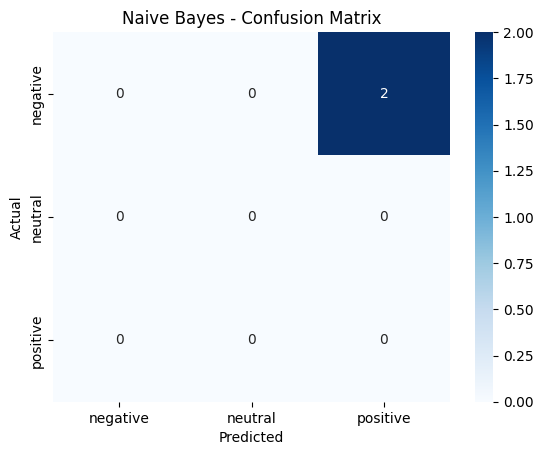


Model: Logistic Regression
Accuracy: 0.0 %
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       2.0
    positive       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



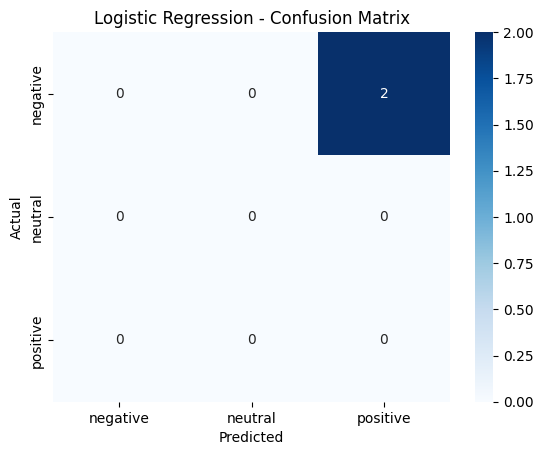

,Model,Accuracy (%)
0,Naive Bayes,0.0
1,Logistic Regression,0.0


Best model: Naive Bayes
Review: This product is excellent and amazing.
Sentiment: POSITIVE
Review: The product is bad and disappointing.
Sentiment: POSITIVE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PROJECT COMPLETED!


In [6]:

# CUSTOMER REVIEW SENTIMENT ANALYSIS
# Excel Dataset + NLP + TF-IDF

!pip -q install openpyxl scikit-learn pandas matplotlib seaborn

import pandas as pd
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Upload Excel file
uploaded = files.upload()
filename = next(iter(uploaded))

# 2. Read Excel file
df = pd.read_excel(filename)

print("Dataset loaded successfully!")
print("Columns:", df.columns.tolist())
print("Shape:", df.shape)
display(df.head())

# 3. Set your actual Excel column names here
# Updated to match the actual columns in your uploaded file
TEXT_COL = "review_text"
LABEL_COL = "sentiment"

# 4. Clean text
def clean_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# 5. Prepare dataset
df = df.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].apply(clean_text)
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip().str.lower()

df = df[df[TEXT_COL] != ""]
df = df.drop_duplicates(subset=[TEXT_COL, LABEL_COL])

print("\nSentiment distribution:")
print(df[LABEL_COL].value_counts())

# 6. Split dataset
X = df[TEXT_COL]
y = df[LABEL_COL]

# Check if any class has fewer than 2 samples to decide on stratification
min_class_count = y.value_counts().min()
if min_class_count < 2:
    print("\nWarning: Some classes have fewer than 2 samples. Splitting without stratification.")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

# 7. Create models
models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000, stop_words="english"
        )),
        ("model", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000, stop_words="english"
        )),
        ("model", LogisticRegression(max_iter=1000))
    ])
}

# 8. Train and evaluate
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results[name] = accuracy_score(y_test, pred)

    print("\nModel:", name)
    print("Accuracy:", round(results[name] * 100, 2), "%")
    print(classification_report(y_test, pred, zero_division=0))

    cm = confusion_matrix(y_test, pred, labels=model.classes_)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=model.classes_,
                yticklabels=model.classes_)
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# 9. Compare accuracy
accuracy_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy (%)": [round(v * 100, 2) for v in results.values()]
})

display(accuracy_df)

# 10. Select best model
best_name = max(results, key=results.get)
best_model = models[best_name]

print("Best model:", best_name)

# 11. Predict a new review
def predict_sentiment(review):
    prediction = best_model.predict([clean_text(review)])[0]
    print("Review:", review)
    print("Sentiment:", prediction.upper())
    return prediction

predict_sentiment("This product is excellent and amazing.")
predict_sentiment("The product is bad and disappointing.")

# 12. Save trained model
import joblib

joblib.dump(best_model, "sentiment_model.pkl")
files.download("sentiment_model.pkl")

# 13. Save accuracy report to Excel
accuracy_df.to_excel("sentiment_accuracy_report.xlsx", index=False)
files.download("sentiment_accuracy_report.xlsx")

print("PROJECT COMPLETED!")